# Kang-style benchmark foundation

**Question:** Can the existing data architecture support a defensible reference
for Kang et al. before the UCL, chronological and temporal-family extensions?

[Parent study](https://doi.org/10.1177/23259671261477532) ·
[Method specification](../../docs/kang_benchmark_spec.md) ·
[Research direction](../../RESEARCH_DESIGN.md)

This is an **approximate retrospective reference**, not an exact reproduction.
It uses 2017–2025 only. The 2026 chronological test remains outside this stage.
All displayed values are read from the reproducible benchmark outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/kang_benchmark.yaml').exists())
REPORT = ROOT / 'reports/kang_benchmark'
TABLES = REPORT / 'tables'
assert (TABLES / 'reference_metrics.csv').exists(), 'Run the benchmark --fit first; see the methods.'
verification = json.loads((REPORT / 'verification.json').read_text())
assert verification['no_2026_rows'] and verification['database_unchanged']
display(pd.Series(verification, name='Verification'))

database_unchanged                                                         True
read_only                                                                  True
earliest_date                                               2017-04-02 00:00:00
latest_date                                                 2025-09-28 00:00:00
no_2026_rows                                                               True
duplicate_appearance_keys                                                     0
cohort_reports_written                                                     True
reference_models_completed                                                    4
source_fingerprint            cde9fc13505711985366ca5a961ab6eadb4a704866ce69...
Name: Verification, dtype: object

## Cohort and comparison

One MLBAM pitcher × regular-season game; P/TWP identities; at least five season
appearances; at most 10% games with any missing required field. Season-majority
role separates starters and relievers. First shoulder/elbow IL placement per
season anchors labels. Only pre-placement case games are used; controls contribute
their season. This season-based design uses retrospective ascertainment.

The primary control definition excludes all IL seasons. A second table follows
the paper's broader Methods wording while excluding unknown-anatomy seasons.
The alternative is counted, not selected based on its predictive performance.

In [2]:
display(pd.read_csv(TABLES / 'cohort_flow.csv'))
support = pd.read_csv(TABLES / 'cohort_support.csv')
display(support[support.window_days.eq(28)][['control_rule','endpoint','role','rows',
    'pitcher_seasons','unique_pitchers','case_seasons','control_seasons',
    'represented_events','positive_rows','earlier_case_negative_rows']])
display(pd.read_csv(TABLES / 'event_eligibility.csv'))

,stage,rows,pitcher_seasons,unique_pitchers
0,all_regular_season_pitching,175708,7491,2298
1,pitchers_and_two_way,174939,7034,2001
2,eligible_pitcher_seasons,171963,5930,1781


,control_rule,endpoint,role,rows,pitcher_seasons,unique_pitchers,case_seasons,control_seasons,represented_events,positive_rows,earlier_case_negative_rows
3,no_any_il,elbow,starter,21114,1021,528,117,904,115,496,932
10,no_any_il,elbow,reliever,86909,2674,1281,217,2457,214,1705,3255
17,no_any_il,shoulder,starter,22009,1090,542,186,904,184,804,1519
24,no_any_il,shoulder,reliever,87989,2744,1285,287,2457,286,2223,3817
31,no_shoulder_elbow_il,elbow,starter,31066,1494,607,117,1377,115,496,932
38,no_shoulder_elbow_il,elbow,reliever,110989,3358,1372,217,3141,214,1705,3255
45,no_shoulder_elbow_il,shoulder,starter,31961,1563,614,186,1377,184,804,1519
52,no_shoulder_elbow_il,shoulder,reliever,112069,3428,1380,287,3141,286,2223,3817


,endpoint,eligible_case,has_preinjury_appearance,case_exclusion,events
0,elbow,False,False,ambiguous first placement/episode,33
1,elbow,False,False,pitcher-season ineligible or absent,155
2,elbow,True,False,NaN,42
3,elbow,True,True,NaN,334
4,shoulder,False,False,ambiguous first placement/episode,28
5,shoulder,False,False,pitcher-season ineligible or absent,101
6,shoulder,True,False,NaN,55
7,shoulder,True,True,NaN,473


## Predictor crosswalk and measurement support

Twenty-three candidate inputs use the dictionary and existing family inventory.
Five are minimal raw-pitch aggregates absent from the appearance table. All-pitch
SD must not be replaced by fastball SD; longitudinal release Y must not be
replaced by extension. Their separate inclusion is explicitly approximate.
Residual NaNs remain available to XGBoost; no full-dataset imputation is fitted.

In [3]:
crosswalk = pd.read_csv(TABLES / 'feature_crosswalk.csv')
display(crosswalk[['kang_concept','feature','project_feature_group','availability','timing_availability']])
missing = pd.read_csv(TABLES / 'feature_missingness.csv')
overview = missing.groupby('feature')[['rows','missing_rows']].sum()
overview['missing_percent'] = 100 * overview.missing_rows / overview.rows
display(overview.sort_values('missing_percent', ascending=False).head(10))

,kang_concept,feature,project_feature_group,availability,timing_availability
0,Age,age_at_appearance,Pitcher background and experience,existing appearance feature,before outing
1,Total pitches,total_pitches,Workload and rest,existing appearance feature,after completed outing
2,Innings pitched,innings_pitched,Appearance performance,existing appearance feature,after completed outing
3,Batters faced,batters_faced,Appearance performance,existing appearance feature,after completed outing
4,Mean velocity,avg_velocity,Velocity,existing appearance feature,after completed outing
5,Maximum velocity,max_velocity,Velocity,existing appearance feature,after completed outing
6,Velocity SD (all pitch types),kang_velocity_sd,Velocity,derived from existing raw field,after completed outing
7,Mean spin rate,spin_avg,Spin,existing appearance feature,after completed outing
8,Maximum spin rate,kang_spin_max,Spin,derived from existing raw field,after completed outing
9,Spin rate SD,kang_spin_sd,Spin,derived from existing raw field,after completed outing


,rows,missing_rows,missing_percent
feature,,,
kang_spin_sd,174939,1141,0.652227
kang_velocity_sd,174939,873,0.499031
spin_avg,174939,478,0.273238
kang_spin_max,174939,478,0.273238
extension_avg,174939,332,0.189780
kang_release_y_avg,174939,247,0.141192
release_z_avg,174939,247,0.141192
kang_release_abs_x_avg,174939,247,0.141192
max_velocity,174939,240,0.137191


## Development window comparison

Fixed XGBoost settings; seven weekly cumulative windows; fold-local gain/correlation
selection inside five-fold development CV. One reserved random-game holdout is
shared across windows. Window and feature decisions are persisted before holdout
scoring. This bounded maximum-CV-AUC procedure **does not reconstruct the published
GAM plateau**. Bars show fold SD, not confidence intervals.

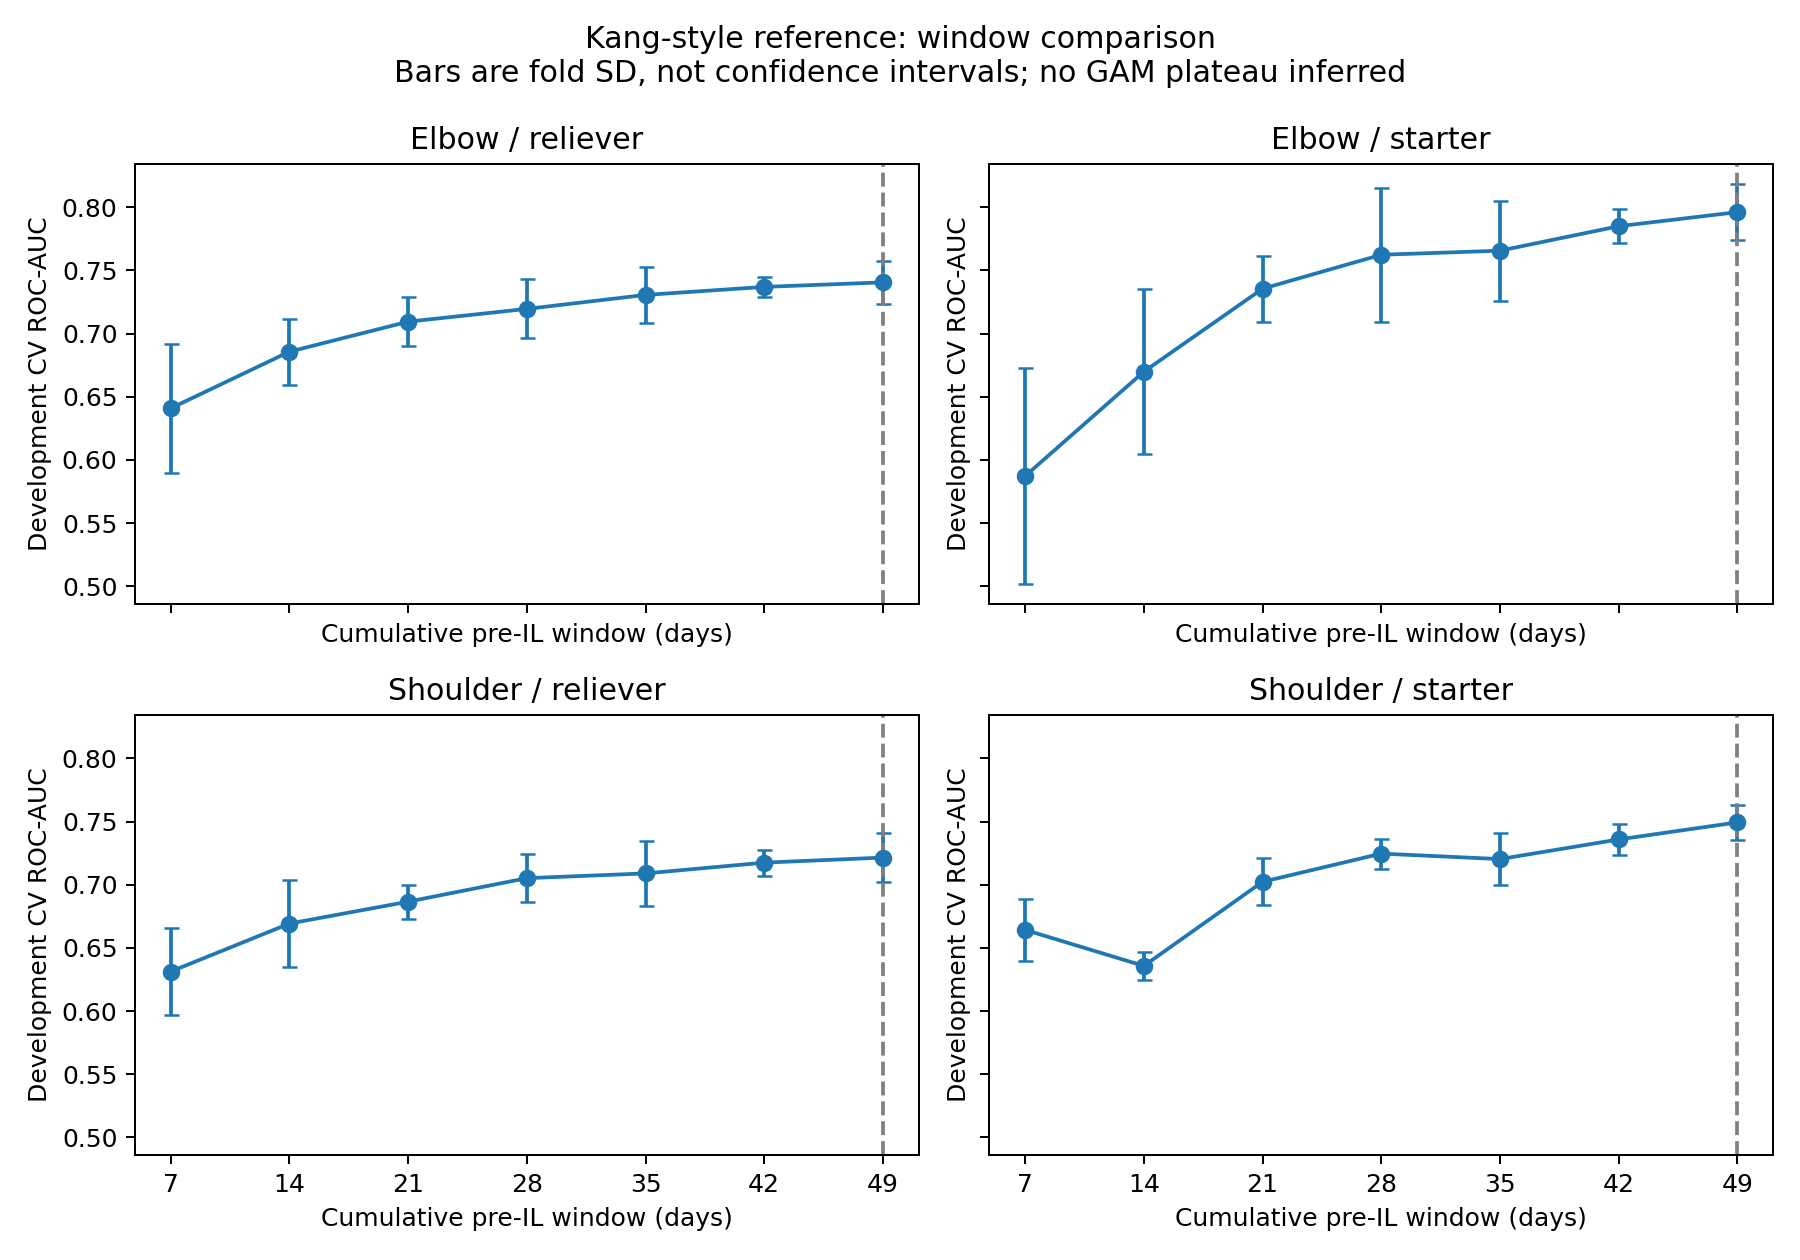

In [4]:
display(Image(filename=str(REPORT / 'figures/development_window_comparison.png')))

## Reserved random-game performance

ROC-AUC is the parent-study metric; AP and prevalence provide rare-event context.
Intervals resample held-out pitcher-seasons 500 times. Class-weighted scores
are not calibrated future injury probabilities. The same pitchers and injury
episodes can be represented in development and holdout; that dependence is
reported, not claimed to be removed by bootstrapping.

In [5]:
metrics = pd.read_csv(TABLES / 'reference_metrics.csv')
display(metrics[['endpoint','role','selected_window_days','selected_features',
    'development_cv_auc','roc_auc','roc_auc_ci_low','roc_auc_ci_high',
    'average_precision','prevalence','pr_lift','represented_events']].round(4))
display(metrics[['endpoint','role','shared_pitchers','holdout_unique_pitchers','shared_case_events',
    'brier','mean_risk','prevalence']].round(4))
display(pd.read_csv(TABLES / 'retained_reference_features.csv').query('retained == True')
    .groupby(['endpoint','role']).feature.agg(list).to_frame())

,endpoint,role,selected_window_days,selected_features,development_cv_auc,roc_auc,roc_auc_ci_low,roc_auc_ci_high,average_precision,prevalence,pr_lift,represented_events
0,elbow,starter,49,18,0.7962,0.8465,0.8160,0.8744,0.1898,0.0357,5.3112,104
1,elbow,reliever,49,18,0.7406,0.7549,0.7269,0.7819,0.0998,0.0296,3.3685,204
2,shoulder,starter,49,18,0.7494,0.7702,0.7377,0.8046,0.1971,0.0569,3.4655,168
3,shoulder,reliever,49,18,0.7215,0.7077,0.6747,0.7358,0.1157,0.0387,2.9890,266


,endpoint,role,shared_pitchers,holdout_unique_pitchers,shared_case_events,brier,mean_risk,prevalence
0,elbow,starter,514,514,110,0.1558,0.3689,0.0357
1,elbow,reliever,1262,1264,211,0.2053,0.4337,0.0296
2,shoulder,starter,531,532,170,0.1886,0.4184,0.0569
3,shoulder,reliever,1261,1262,266,0.2118,0.4509,0.0387


feature
endpoint role                                                       
elbow    reliever  [si_usage_pct, cu_usage_pct, kang_release_y_av...
         starter   [extension_avg, innings_pitched, kang_velocity...
shoulder reliever  [extension_avg, age_at_appearance, kang_spin_s...
         starter   [kc_usage_pct, extension_avg, age_at_appearanc...

## Interpretation and next step

The benchmark is executable, with tracking missingness and feature support
quantified above. A best-scoring window at the grid boundary is **not** evidence
that Kang's plateau estimates were replicated. Endpoint,
control, earlier-case-game and feature-name ambiguities remain material.

Random holdout discrimination cannot distinguish learned persistent pitcher
profiles from imminent injury signals, and does not validate useful alert lead
time. No alert thresholds, new predictors, alternative learner search, PCA/PLS
or 2026 model-selection decisions were introduced.

Resolve and freeze the qualified reference. Then change only the broad elbow
endpoint to adjudicated UCL, followed by the chronological and limited temporal
family comparisons. Preserve the earlier analyses as hypothesis-generating
context, not independent confirmation.

In [6]:
display(pd.read_csv(ROOT / 'docs/kang_benchmark_comparison.csv'))

,Component,Kang et al.,Our benchmark,Planned extension,match_status
0,Period,2017–2025 regular seasons,Same years and game type R,Expanded historical chronological training,exact design period
1,Observation,Pitcher-game; season-based eligibility,One MLBAM pitcher × game ID; doubleheaders rem...,Preserve completed-outing landmark,exact observation concept
2,Endpoint,First shoulder **or** elbow IL event per pitch...,Initial official-transaction anatomy; first co...,Adjudicated UCL-specific endpoint,approximate source/QA
3,Reference date,IL placement,"`transaction_date`, not retroactive effective ...",Existing adjudicated earliest defensible date ...,exact IL-placement proxy; approximate source
4,Sources,Savant/Baseball Reference; Spotrac/Pro Sports ...,Existing Savant + official boxscore/people + M...,Retain provenance and UCL adjudication evidence,approximate source coverage
5,Exposure/missingness,At least 5 season appearances; at most 10% gam...,Same thresholds on 23 declared inputs; residua...,Landmark eligibility and historical support rules,exact thresholds; approximate required fields
6,Role,Majority role in season; innings break ties,"Official appearance starts; count majority, th...",Role known at prediction time,approximate tie handling
7,Controls,Methods: no shoulder/elbow IL; Results: no IL,Primary no IL; target-specific controls counte...,Full prospective-style risk set and competing-...,unresolved publication ambiguity
8,Window,Cumulative 7–49 days pre-IL,Seven fixed weekly windows; earlier pre-IL gam...,Prespecified lead-time/family contrasts,approximate grid and outside-window treatment
9,Predictors,"Age, outing workload, release/velocity/spin, p...",23 mapped inputs; 18 existing plus 5 necessary...,"Limited original families, not all engineered ...",approximate mapped feature implementation
